# Rediscovering Kepler's Three Laws — an End-to-End Machine Learning Project

This notebook contains all the code of the guide `index.html` (same folder).
Run it top to bottom. Every figure of the guide is produced here and saved in `images/`.

**Data used (all real):**
* Tycho Brahe's naked-eye declinations of Mars, 1582–1600 (*Tychonis Brahe Dani Opera Omnia*, digitized by W. Pafko, spreadsheet by C. Yamahata)
* NASA/JPL Horizons ephemerides (geocentric positions of Mars and the Sun) — a NASA model fitted to real observations
* NASA Planetary Fact Sheet and Jovian Satellite Fact Sheet

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Ignore useless warnings
import warnings
warnings.filterwarnings(action="ignore", message="^internal gelsd")

## Get the Data

In [2]:
import gzip
import io
import urllib.request

DATASETS_PATH = os.path.join("datasets")
TYCHO_PATH = os.path.join(DATASETS_PATH, "tycho")
# Wayne Pafko's transcription of Tycho's Mars observations (Opera Omnia, vols. 10-13),
# as re-published in Christophe Yamahata's spreadsheet (Observable, 2026)
TYCHO_URL = ("https://static.observableusercontent.com/files/"
             "9c91f89b993ce752c10b2147650ab95060d2505719991aa3919a009192739204"
             "ba92d517ea43392c7cdd38edf151052472204e58f27ecd363835bb3928813846")

def fetch_tycho_data(tycho_url=TYCHO_URL, tycho_path=TYCHO_PATH):
    """Download the spreadsheet once and keep only the raw observation sheet."""
    os.makedirs(tycho_path, exist_ok=True)
    csv_path = os.path.join(tycho_path, "tycho_mars_declinations.csv")
    if os.path.exists(csv_path):            # already downloaded
        return csv_path
    raw = urllib.request.urlopen(tycho_url, timeout=120).read()
    if raw[:2] == b"\x1f\x8b":               # some servers send it gzipped
        raw = gzip.decompress(raw)
    sheet = pd.read_excel(io.BytesIO(raw), sheet_name=0, header=5).iloc[:, 1:21]
    sheet.columns = ["year_raw", "day_text", "time_text", "quote", "volume", "page",
                     "_", "year", "month", "day", "day_adj", "hour", "minute",
                     "days_1ad", "date_dec", "_2", "dec_deg", "dec_min", "dec_sec",
                     "declination"]
    sheet = sheet.dropna(subset=["year", "month", "day", "declination"])
    keep = ["year", "month", "day", "day_text", "time_text", "quote", "volume",
            "page", "dec_deg", "dec_min", "dec_sec", "declination"]
    sheet[keep].to_csv(csv_path, index=False)
    return csv_path

In [3]:
def load_tycho_data(tycho_path=TYCHO_PATH):
    csv_path = fetch_tycho_data(tycho_path=tycho_path)
    return pd.read_csv(csv_path)

tycho = load_tycho_data()
tycho.head()

,year,month,day,day_text,time_text,quote,volume,page,dec_deg,dec_min,dec_sec,declination
0,1582,11,12,"DIE 12 NOUEMBRIS, MANE.",NaN,Declinatio [MS] 23 7 B,10.0,174.0,23.0,7.0,NaN,23.116667
1,1582,12,30,DIE 30 DECEMBRIS,NaN,Afc. R. [MS] 107o 56' Declin. 26o 36' B.,10.0,197.0,26.0,36.0,NaN,26.600000
2,1582,12,30,DIE 30 DECEMBRIS,NaN,Declin. [MS] 26 37 30 B,10.0,198.0,26.0,37.0,30.0,26.625000
3,1582,12,27,DIE 27 DECEMBRIS,NaN,declinatio [MS] 26o 22 1/3' et Afcenfio Recta...,10.0,200.0,26.0,22.0,20.0,26.372222
4,1583,1,18,"DIE 18 JANUARIJ, VESPERI.",NaN,Declinatio 27 18 minus bona,10.0,244.0,27.0,18.0,NaN,27.300000


In [4]:
tycho.info()

<class 'pandas.DataFrame'>
RangeIndex: 940 entries, 0 to 939
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   year         940 non-null    int64  
 1   month        940 non-null    int64  
 2   day          940 non-null    int64  
 3   day_text     940 non-null    str    
 4   time_text    902 non-null    str    
 5   quote        936 non-null    str    
 6   volume       938 non-null    float64
 7   page         938 non-null    float64
 8   dec_deg      940 non-null    float64
 9   dec_min      940 non-null    float64
 10  dec_sec      588 non-null    float64
 11  declination  940 non-null    float64
dtypes: float64(6), int64(3), str(3)
memory usage: 88.3 KB


In [5]:
tycho["volume"].value_counts().sort_index()

volume
10.0     37
11.0    173
12.0    630
13.0     98
Name: count, dtype: int64

In [6]:
tycho.describe()

,year,month,day,volume,page,dec_deg,dec_min,dec_sec,declination
count,940.000000,940.000000,940.000000,938.000000,938.000000,940.000000,940.000000,588.000000,940.000000
mean,1592.258511,7.154255,17.564894,11.841151,276.087420,14.326596,27.918085,30.294218,4.516227
std,3.406156,3.847275,9.039202,0.649548,146.923581,6.689105,15.106533,12.112625,15.614359
min,1582.000000,1.000000,1.000000,10.000000,43.000000,0.000000,0.000000,0.000000,-27.975000
25%,1590.000000,3.000000,10.000000,12.000000,145.000000,10.000000,17.000000,20.000000,-11.081250
50%,1593.000000,9.000000,18.000000,12.000000,288.000000,16.000000,27.000000,30.000000,9.443056
75%,1595.000000,10.000000,26.000000,12.000000,445.750000,17.000000,38.000000,40.000000,17.458333
max,1600.000000,12.000000,31.000000,13.000000,459.000000,27.000000,59.000000,50.000000,27.300000


Saving figure attribute_histogram_plots


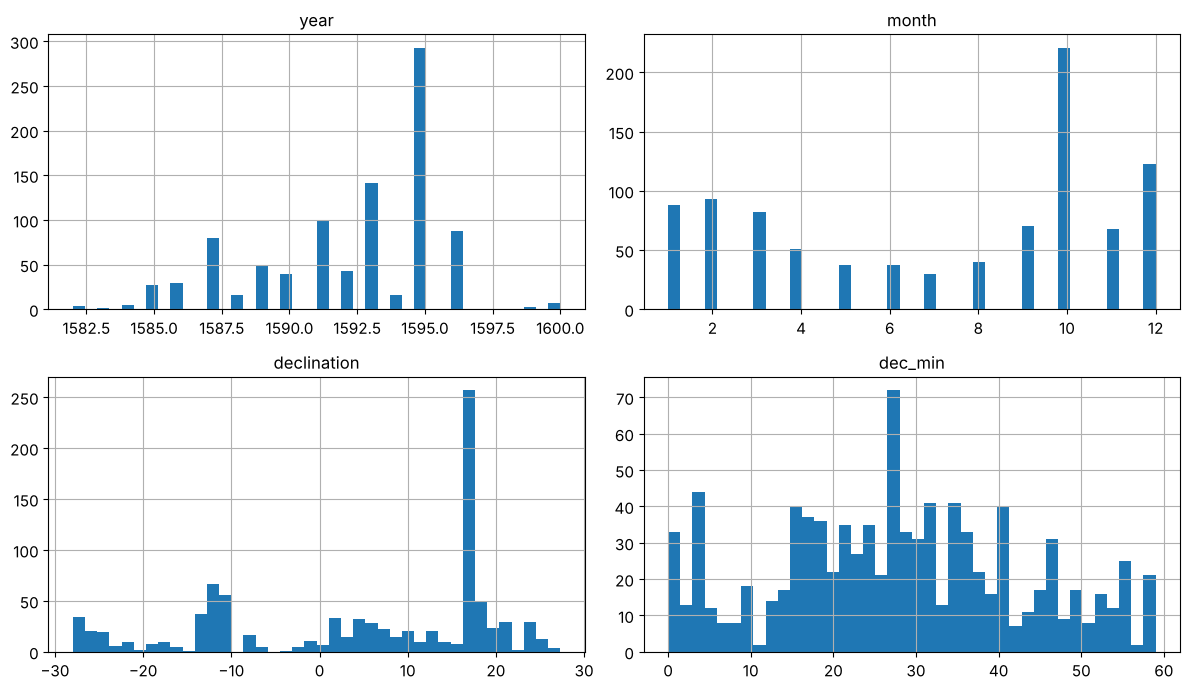

In [7]:
tycho[["year", "month", "declination", "dec_min"]].hist(bins=40, figsize=(12, 7))
save_fig("attribute_histogram_plots")
plt.show()

### Fetching NASA/JPL Horizons ephemerides

In [8]:
import urllib.parse

NASA_PATH = os.path.join(DATASETS_PATH, "nasa")
HORIZONS_API = "https://ssd.jpl.nasa.gov/api/horizons.api"

def fetch_horizons(target, start, stop, step, quantities, filename,
                   center="500@399", nasa_path=NASA_PATH):
    """Ask JPL Horizons for an observer table and cache it as CSV.
    target: '4' = Mars barycenter, '10' = Sun; center '500@399' = Earth's centre."""
    os.makedirs(nasa_path, exist_ok=True)
    csv_path = os.path.join(nasa_path, filename)
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    params = dict(format="text", COMMAND=f"'{target}'", OBJ_DATA="NO",
                  MAKE_EPHEM="YES", EPHEM_TYPE="OBSERVER", CENTER=f"'{center}'",
                  START_TIME=f"'{start}'", STOP_TIME=f"'{stop}'",
                  STEP_SIZE=f"'{step}'", QUANTITIES=f"'{quantities}'",
                  CSV_FORMAT="YES", CAL_FORMAT="JD", ANG_FORMAT="DEG")
    url = HORIZONS_API + "?" + urllib.parse.urlencode(params)
    text = urllib.request.urlopen(url, timeout=180).read().decode()
    header = text[:text.index("$$SOE")].strip().splitlines()[-2]
    body = text[text.index("$$SOE") + 5:text.index("$$EOE")].strip()
    cols = [c.strip() for c in header.split(",")]
    rows = [[x.strip() for x in line.split(",")] for line in body.splitlines()]
    df = pd.DataFrame(rows, columns=cols[:len(rows[0])])
    df = df.loc[:, [c for c in df.columns if c]]          # drop empty columns
    df = df.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
    df.to_csv(csv_path, index=False)
    return df

# Mars as seen from the centre of the Earth, one row per day, 1582-1600
mars_geo = fetch_horizons("4", "JD 2298900.5", "JD 2305500.5", "1d", "2,31,20",
                          "horizons_mars_geocentric_1582_1600.csv")
# The Sun as seen from the centre of the Earth, same dates
sun_geo = fetch_horizons("10", "JD 2298900.5", "JD 2305500.5", "1d", "31,20",
                         "horizons_sun_geocentric_1582_1600.csv")
mars_geo.head()

,Date_________JDUT,R.A._(a-app),DEC_(a-app),ObsEcLon,ObsEcLat,delta,deldot
0,2298900.5,286.72527,-23.41019,285.314648,-0.802612,2.299836,-6.509204
1,2298901.5,287.55260,-23.32959,286.078399,-0.811809,2.296071,-6.529239
2,2298902.5,288.37952,-23.24468,286.842706,-0.820956,2.292294,-6.548996
3,2298903.5,289.20596,-23.15548,287.607553,-0.830055,2.288506,-6.568436
4,2298904.5,290.03184,-23.06200,288.372921,-0.839102,2.284707,-6.587491


In [9]:
mars_geo.columns = ["jd", "ra", "dec", "ecl_lon", "ecl_lat", "delta", "deldot"]
sun_geo.columns = ["jd", "ecl_lon", "ecl_lat", "delta", "deldot"]
sun_geo.head(3)

,jd,ecl_lon,ecl_lat,delta,deldot
0,2298900.5,307.839562,-0.000152,0.985585,0.278154
1,2298901.5,308.854107,-0.000129,0.985747,0.285084
2,2298902.5,309.868411,-0.000099,0.985914,0.291464


In [10]:
def fetch_fact_sheet(url, filename, nasa_path=NASA_PATH):
    os.makedirs(nasa_path, exist_ok=True)
    html_path = os.path.join(nasa_path, filename)
    if not os.path.exists(html_path):
        urllib.request.urlretrieve(url, html_path)
    return pd.read_html(html_path)

planet_tables = fetch_fact_sheet("https://nssdc.gsfc.nasa.gov/planetary/factsheet/",
                                 "planetary_fact_sheet.html")
jovian_tables = fetch_fact_sheet(
    "https://nssdc.gsfc.nasa.gov/planetary/factsheet/joviansatfact.html",
    "jovian_satellite_fact_sheet.html")

table = planet_tables[0]
facts = table.iloc[1:].set_index(0)          # first column holds the row names
facts.columns = table.iloc[0, 1:].values     # first row holds the planet names
facts = facts[facts.index.notna()]
planets = pd.DataFrame({
    "a_million_km": pd.to_numeric(facts.loc["Distance from Sun (106 km)"]
                                  .str.replace("*", "", regex=False)),
    "period_days": pd.to_numeric(facts.loc["Orbital Period (days)"]
                                 .str.replace("*", "", regex=False)),
    "eccentricity": pd.to_numeric(facts.loc["Orbital Eccentricity"]),
}).drop(index="MOON")
planets

,a_million_km,period_days,eccentricity
MERCURY,57.9,88.0,0.206
VENUS,108.2,224.7,0.007
EARTH,149.6,365.2,0.017
MARS,228.0,687.0,0.094
JUPITER,778.5,4331.0,0.049
SATURN,1432.0,10747.0,0.052
URANUS,2867.0,30589.0,0.047
NEPTUNE,4515.0,59800.0,0.010
PLUTO,5906.4,90560.0,0.244


In [11]:
orbits = jovian_tables[1].set_index(0)
galilean = orbits.loc[["Io (I)", "Europa (II)", "Ganymede (III)", "Callisto (IV)"]]
moons = pd.DataFrame({
    "a_thousand_km": pd.to_numeric(galilean.iloc[:, 0]),
    "period_days": pd.to_numeric(galilean.iloc[:, 2]),
})
moons

,a_thousand_km,period_days
0,,
Io (I),421.8,1.769138
Europa (II),671.1,3.551181
Ganymede (III),1070.4,7.154553
Callisto (IV),1882.7,16.689017


## Create a Test Set

In [12]:
def julian_calendar_to_jd(year, month, day):
    """Julian Day Number at 0h UT of a date in the *Julian* calendar
    (Denmark kept the Julian calendar until 1700)."""
    year, month, day = (np.asarray(v, dtype=int) for v in (year, month, day))
    a = (14 - month) // 12
    y = year + 4800 - a
    m = month + 12 * a - 3
    return day + (153 * m + 2) // 5 + 365 * y + y // 4 - 32083 - 0.5

julian_calendar_to_jd(1600, 1, 1)

np.float64(2305457.5)

In [13]:
# Mars is only observable for months around each opposition (every ~780 days).
# We label every observation with its "apparition" so that nights of the same
# season always end up in the same set.
SYNODIC_PERIOD = 779.94   # days, mean time between two oppositions
jd_date = julian_calendar_to_jd(tycho["year"], tycho["month"], tycho["day"])
tycho["apparition"] = np.floor((jd_date - jd_date.min() + 200) / SYNODIC_PERIOD).astype(int)
tycho["apparition"].value_counts().sort_index()

apparition
0      5
1     32
2    110
3     83
4    162
5    160
6    378
8     10
Name: count, dtype: int64

In [14]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(tycho, groups=tycho["apparition"]))
train_set = tycho.iloc[train_idx].copy()
test_set = tycho.iloc[test_idx].copy()
print(len(train_set), "train +", len(test_set), "test")
print("test apparitions:", sorted(test_set["apparition"].unique()))

748 train + 192 test
test apparitions: [np.int64(1), np.int64(5)]


In [15]:
from sklearn.model_selection import train_test_split

rnd_train, rnd_test = train_test_split(tycho, test_size=0.2, random_state=42)
same_night = rnd_test.apply(lambda r: ((rnd_train["year"] == r["year"]) &
                                        (rnd_train["month"] == r["month"]) &
                                        (rnd_train["day"] == r["day"])).any(), axis=1)
print(f"{same_night.mean():.0%} of the random test rows have a twin from the same night in the training set")

90% of the random test rows have a twin from the same night in the training set


## Discover and Visualize the Data to Gain Insights

In [16]:
mars = train_set.copy()

Saving figure tycho_declination_vs_time


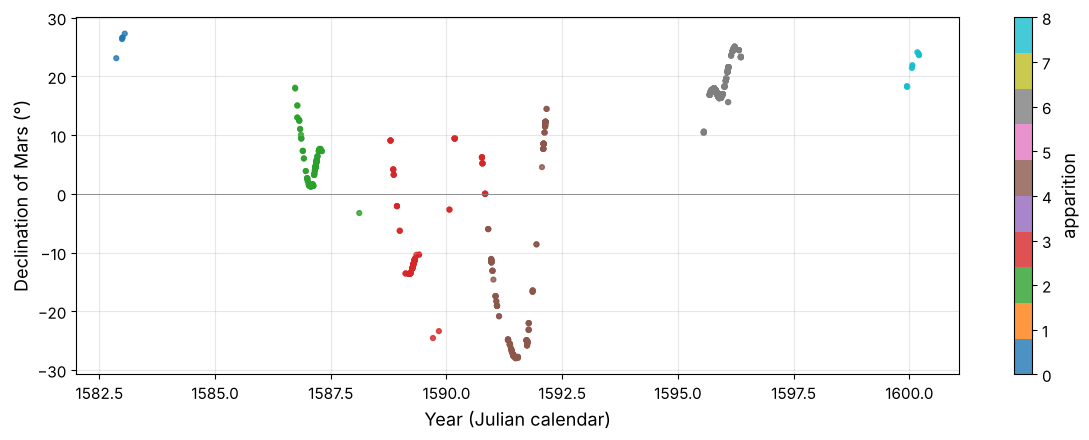

In [17]:
fig, ax = plt.subplots(figsize=(12, 4.5))
year_frac = mars["year"] + (mars["month"] - 1) / 12 + mars["day"] / 365
sc = ax.scatter(year_frac, mars["declination"], c=mars["apparition"], cmap="tab10",
                s=12, alpha=0.8)
ax.set_xlabel("Year (Julian calendar)")
ax.set_ylabel("Declination of Mars (°)")
ax.axhline(0, color="gray", lw=0.6)
ax.grid(alpha=0.3)
plt.colorbar(sc, label="apparition")
save_fig("tycho_declination_vs_time")
plt.show()

Saving figure retrograde_loops


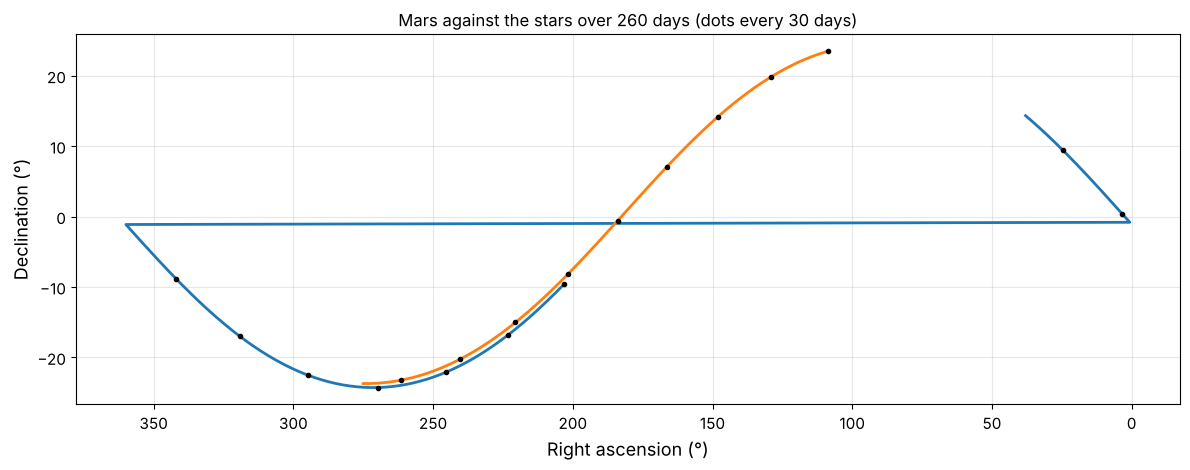

In [18]:
fig, ax = plt.subplots(figsize=(12, 4.8))
for start in (2299500, 2302700):
    seg = mars_geo[(mars_geo["jd"] > start) & (mars_geo["jd"] < start + 260)]
    ax.plot(seg["ra"], seg["dec"], lw=2)
    for k in range(0, len(seg), 30):
        ax.plot(seg["ra"].iloc[k], seg["dec"].iloc[k], "ko", ms=3)
ax.invert_xaxis()                         # east is to the left on a sky map
ax.set_xlabel("Right ascension (°)")
ax.set_ylabel("Declination (°)")
ax.set_title("Mars against the stars over 260 days (dots every 30 days)")
ax.grid(alpha=0.3)
save_fig("retrograde_loops")
plt.show()

Saving figure periodogram_plot


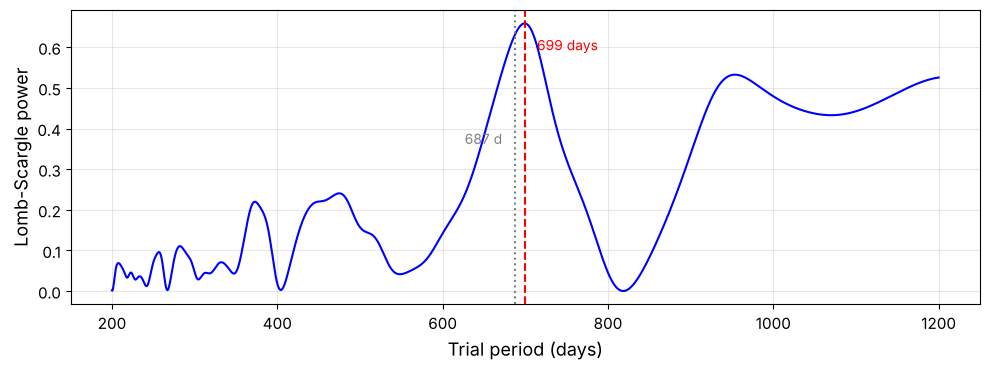

np.float64(699.1247811952989)

In [19]:
from scipy.signal import lombscargle

t_days = (jd_date[train_idx] - jd_date.min()).astype(float)
y_dec = mars["declination"].values - mars["declination"].mean()
periods = np.linspace(200, 1200, 4000)
power = lombscargle(t_days, y_dec, 2 * np.pi / periods, normalize=True)
best_period = periods[np.argmax(power)]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(periods, power, "b-")
ax.axvline(best_period, color="r", ls="--")
ax.axvline(686.98, color="gray", ls=":")
ax.text(686.98 - 15, power.max() * 0.55, "687 d", color="gray", ha="right")
ax.text(best_period + 15, power.max() * 0.9, f"{best_period:.0f} days", color="r")
ax.set_xlabel("Trial period (days)")
ax.set_ylabel("Lomb-Scargle power")
ax.grid(alpha=0.3)
save_fig("periodogram_plot")
plt.show()
best_period

In [20]:
# Earth laps Mars: 1/synodic = 1/year - 1/sidereal
year = 365.2564                        # sidereal year, known to Tycho to seconds
synodic_from_peak = 1 / (1 / year - 1 / best_period)
synodic_from_copernicus = 1 / (1 / year - 1 / 686.98)
synodic_from_peak, synodic_from_copernicus

(np.float64(764.8517053814926), 779.9360745434901)

In [21]:
# Kepler's trick: Mars returns to the same point of its orbit every 687 days,
# while the Earth does not. Two sight lines, 687 days apart, cross at Mars.
lam_mars = np.radians(mars_geo["ecl_lon"].values)
lam_sun = np.radians(sun_geo["ecl_lon"].values)
earth_x = -sun_geo["delta"].values * np.cos(lam_sun)   # Earth = minus the Sun's
earth_y = -sun_geo["delta"].values * np.sin(lam_sun)   # geocentric position
jd = mars_geo["jd"].values

def triangulate(i, period=686.98):
    j = np.searchsorted(jd, jd[i] + period)
    u1 = np.array([np.cos(lam_mars[i]), np.sin(lam_mars[i])])
    u2 = np.array([np.cos(lam_mars[j]), np.sin(lam_mars[j])])
    A = np.column_stack([u1, -u2])
    if abs(np.linalg.det(A)) < 0.2:           # sight lines almost parallel
        return None
    b = np.array([earth_x[j] - earth_x[i], earth_y[j] - earth_y[i]])
    s1, s2 = np.linalg.solve(A, b)             # distances Earth->Mars (AU)
    return jd[i], earth_x[i] + s1 * u1[0], earth_y[i] + s1 * u1[1]

points = [triangulate(i) for i in range(0, len(jd) - 700, 5)]
orbit = pd.DataFrame([p for p in points if p is not None], columns=["jd", "x", "y"])
orbit["r"] = np.hypot(orbit["x"], orbit["y"])
orbit["theta"] = np.degrees(np.arctan2(orbit["y"], orbit["x"])) % 360
orbit.describe().loc[["count", "min", "max"]]

,jd,x,y,r,theta
count,894.0,894.000000,894.000000,894.000000,894.000000
min,2298900.5,-1.646304,-1.449170,1.380493,0.209396
max,2304800.5,1.404391,1.596116,1.668593,359.975143


Saving figure kepler_triangulation_plot


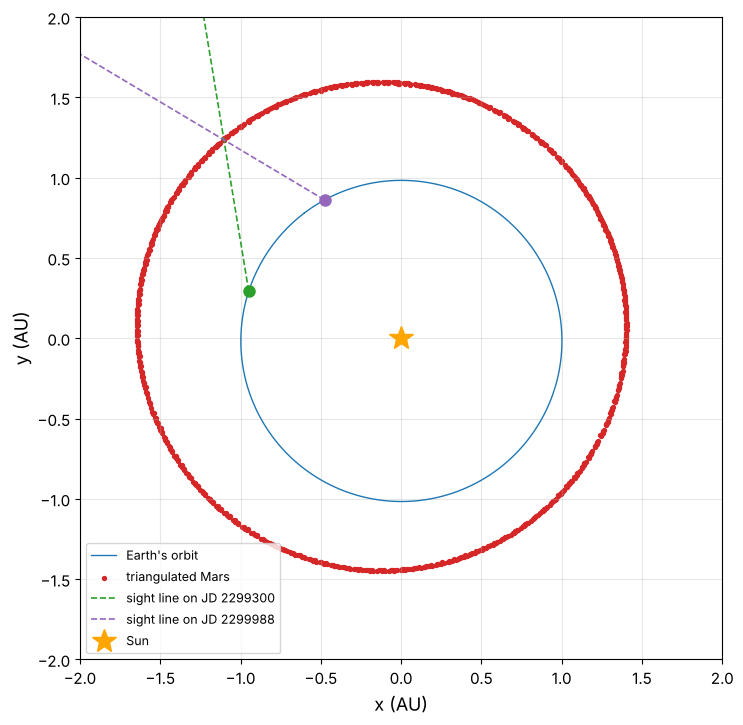

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
i = 400
j = np.searchsorted(jd, jd[i] + 686.98)
ax.plot(earth_x[:366], earth_y[:366], color="tab:blue", lw=1, label="Earth's orbit")
ax.scatter(orbit["x"], orbit["y"], s=8, c="tab:red", label="triangulated Mars")
for k, col in ((i, "tab:green"), (j, "tab:purple")):
    ax.plot(earth_x[k], earth_y[k], "o", color=col, ms=8)
    ax.plot([earth_x[k], earth_x[k] + 3 * np.cos(lam_mars[k])],
            [earth_y[k], earth_y[k] + 3 * np.sin(lam_mars[k])], color=col, lw=1.2,
            ls="--", label=f"sight line on JD {jd[k]:.0f}")
ax.plot(0, 0, "*", color="orange", ms=18, label="Sun")
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x (AU)"); ax.set_ylabel("y (AU)")
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.3)
save_fig("kepler_triangulation_plot")
plt.show()

In [23]:
from sklearn.linear_model import LinearRegression

# A conic is A x² + B xy + C y² + D x + E y = 1  ->  linear in the 5 coefficients!
X_conic = np.c_[orbit.x**2, orbit.x * orbit.y, orbit.y**2, orbit.x, orbit.y]
conic_reg = LinearRegression(fit_intercept=False)
conic_reg.fit(X_conic, np.ones(len(orbit)))
A, B, C, D, E = conic_reg.coef_

def conic_geometry(A, B, C, D, E):
    Q = np.array([[A, B / 2], [B / 2, C]])
    center = np.linalg.solve(2 * Q, -np.array([D, E]))
    F = 1 + center @ Q @ center
    eigval, eigvec = np.linalg.eigh(Q)
    semi_axes = np.sqrt(F / eigval)
    a, b = semi_axes.max(), semi_axes.min()
    return center, a, b, np.sqrt(1 - (b / a) ** 2), B**2 - 4 * A * C

center, a_fit, b_fit, e_fit, discriminant = conic_geometry(A, B, C, D, E)
print(f"discriminant B²-4AC = {discriminant:.3f} (negative => ellipse)")
print(f"a = {a_fit:.4f} AU, b = {b_fit:.4f} AU, e = {e_fit:.4f}")
print(f"centre is {np.hypot(*center):.4f} AU from the Sun; a*e = {a_fit * e_fit:.4f} AU")

discriminant B²-4AC = -0.759 (negative => ellipse)
a = 1.5248 AU, b = 1.5187 AU, e = 0.0898
centre is 0.1416 AU from the Sun; a*e = 0.1369 AU


Saving figure fitted_ellipse_plot


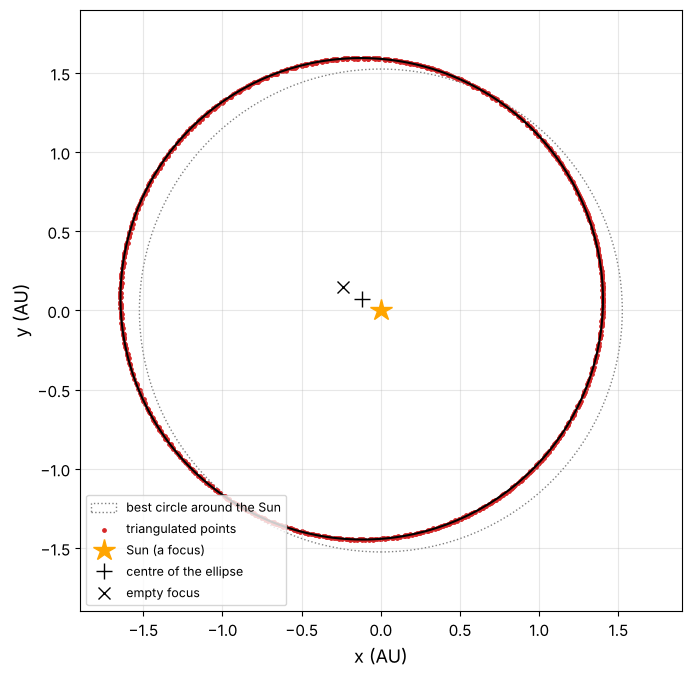

In [24]:
fig, ax = plt.subplots(figsize=(7, 7))
gx, gy = np.meshgrid(np.linspace(-1.9, 1.9, 400), np.linspace(-1.9, 1.9, 400))
ax.contour(gx, gy, A*gx**2 + B*gx*gy + C*gy**2 + D*gx + E*gy, levels=[1], colors="k")
circle = plt.Circle((0, 0), orbit["r"].mean(), fill=False, ls=":", color="gray",
                    label="best circle around the Sun")
ax.add_patch(circle)
ax.scatter(orbit.x, orbit.y, s=6, c="tab:red", label="triangulated points")
ax.plot(0, 0, "*", color="orange", ms=16, label="Sun (a focus)")
ax.plot(*center, "k+", ms=12, label="centre of the ellipse")
focus2 = 2 * center
ax.plot(*focus2, "kx", ms=9, label="empty focus")
ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlabel("x (AU)"); ax.set_ylabel("y (AU)")
ax.legend(loc="lower left", fontsize=9)
save_fig("fitted_ellipse_plot")
plt.show()

In [25]:
orbit = orbit.sort_values("jd").reset_index(drop=True)
gaps = np.diff(orbit["jd"].values)
theta_unwrapped = np.unwrap(np.radians(orbit["theta"].values))
orbit["theta_dot"] = np.gradient(theta_unwrapped, orbit["jd"].values)  # rad/day
orbit.loc[np.r_[gaps, 99] > 6, "theta_dot"] = np.nan                   # skip gaps
orbit[["r", "theta_dot"]].corr()

,r,theta_dot
r,1.000000,-0.997437
theta_dot,-0.997437,1.000000


Saving figure angular_speed_vs_distance


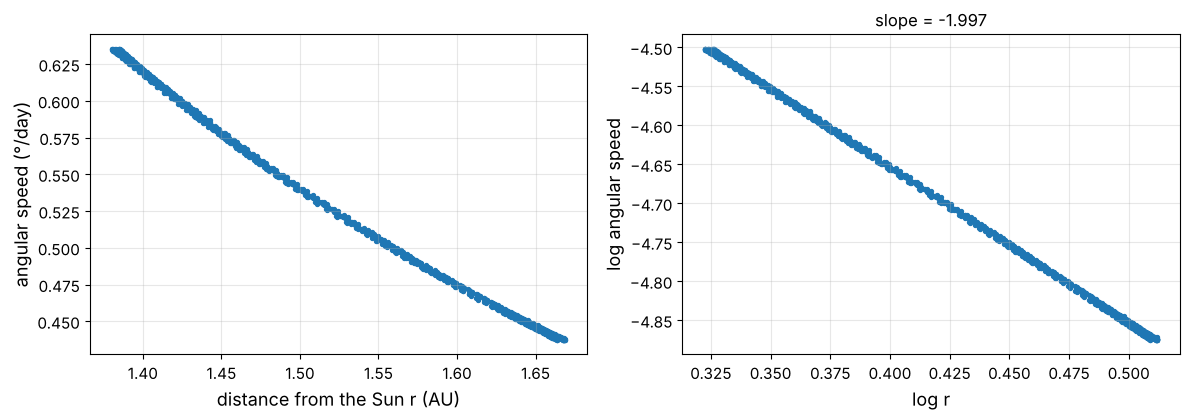

np.float64(-1.9968802863962498)

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].scatter(orbit["r"], np.degrees(orbit["theta_dot"]), s=8)
axes[0].set_xlabel("distance from the Sun r (AU)")
axes[0].set_ylabel("angular speed (°/day)")
axes[0].grid(alpha=0.3)
axes[1].scatter(np.log(orbit["r"]), np.log(orbit["theta_dot"]), s=8)
slope = np.polyfit(np.log(orbit["r"]).values[orbit.theta_dot.notna()],
                   np.log(orbit["theta_dot"]).values[orbit.theta_dot.notna()], 1)[0]
axes[1].set_title(f"slope = {slope:.3f}")
axes[1].set_xlabel("log r"); axes[1].set_ylabel("log angular speed")
axes[1].grid(alpha=0.3)
save_fig("angular_speed_vs_distance")
plt.show()
slope

In [27]:
orbit["areal_velocity"] = 0.5 * orbit["r"] ** 2 * orbit["theta_dot"]   # AU² per day
orbit[["theta_dot", "areal_velocity"]].describe().loc[["mean", "std", "min", "max"]]

,theta_dot,areal_velocity
mean,0.009249,0.010602
std,0.001229,0.000027
min,0.007633,0.010552
max,0.011087,0.010655


Saving figure areal_velocity_plot


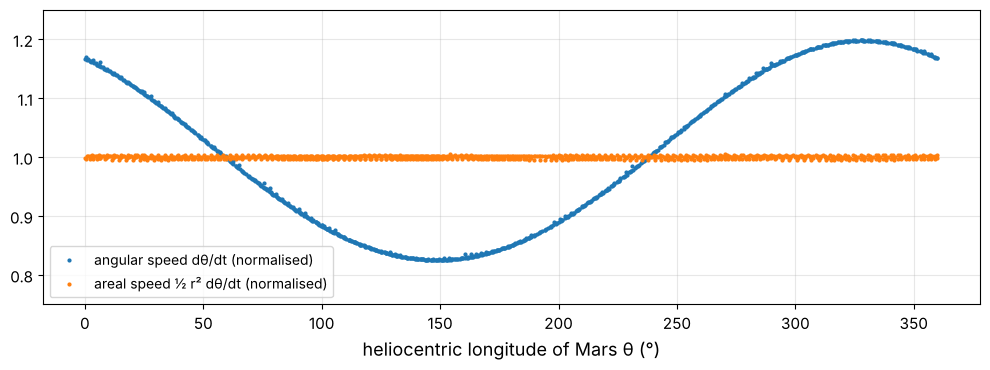

In [28]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(orbit["theta"], orbit["theta_dot"] / orbit["theta_dot"].mean(), ".",
        ms=4, label="angular speed dθ/dt (normalised)")
ax.plot(orbit["theta"], orbit["areal_velocity"] / orbit["areal_velocity"].mean(), ".",
        ms=4, label="areal speed ½ r² dθ/dt (normalised)")
ax.set_xlabel("heliocentric longitude of Mars θ (°)")
ax.set_ylim(0.75, 1.25); ax.grid(alpha=0.3); ax.legend()
save_fig("areal_velocity_plot")
plt.show()

In [29]:
AU_KM = 149.6e6
harmony = planets.copy()
harmony["a_AU"] = harmony["a_million_km"] * 1e6 / AU_KM
harmony["period_years"] = harmony["period_days"] / 365.25
harmony[["a_AU", "period_years"]]

,a_AU,period_years
MERCURY,0.387032,0.240931
VENUS,0.723262,0.615195
EARTH,1.000000,0.999863
MARS,1.524064,1.880903
JUPITER,5.203877,11.857632
SATURN,9.572193,29.423682
URANUS,19.164439,83.748118
NEPTUNE,30.180481,163.723477
PLUTO,39.481283,247.939767


Saving figure period_vs_distance_plot


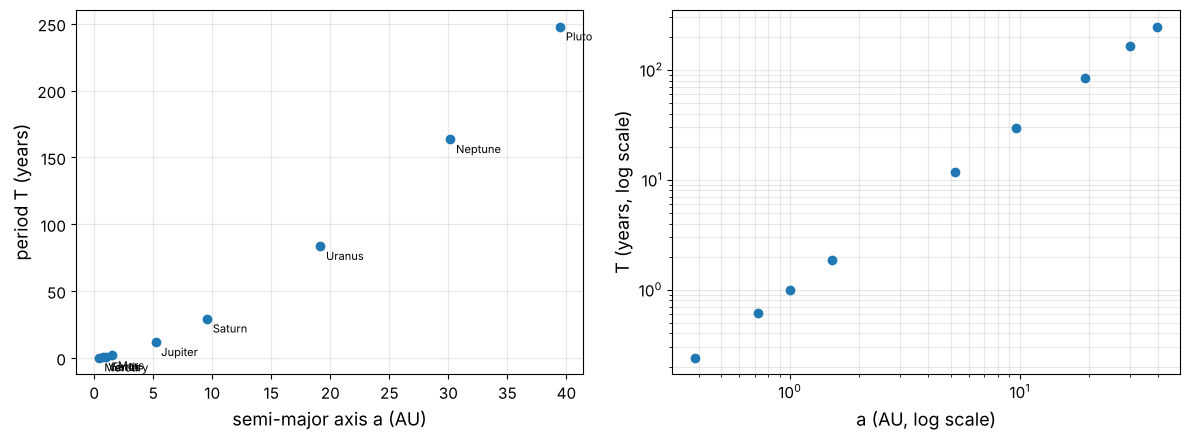

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(harmony["a_AU"], harmony["period_years"], "o")
for name, row in harmony.iterrows():
    axes[0].annotate(name.title(), (row.a_AU, row.period_years), fontsize=8,
                     xytext=(4, -10), textcoords="offset points")
axes[0].set_xlabel("semi-major axis a (AU)"); axes[0].set_ylabel("period T (years)")
axes[1].loglog(harmony["a_AU"], harmony["period_years"], "o")
axes[1].set_xlabel("a (AU, log scale)"); axes[1].set_ylabel("T (years, log scale)")
for ax in axes: ax.grid(alpha=0.3, which="both")
save_fig("period_vs_distance_plot")
plt.show()

In [31]:
harmony["T2_over_a3"] = harmony["period_years"] ** 2 / harmony["a_AU"] ** 3
harmony["T_over_a"] = harmony["period_years"] / harmony["a_AU"]
harmony[["T_over_a", "T2_over_a3"]].round(3)

,T_over_a,T2_over_a3
MERCURY,0.623,1.001
VENUS,0.851,1.000
EARTH,1.000,1.000
MARS,1.234,0.999
JUPITER,2.279,0.998
SATURN,3.074,0.987
URANUS,4.370,0.996
NEPTUNE,5.425,0.975
PLUTO,6.280,0.999


## Prepare the Data for Machine Learning Algorithms

In [32]:
mars = train_set.drop("declination", axis=1)
mars_labels = train_set["declination"].copy()

In [33]:
mars["time_text"].isna().sum(), mars["time_text"].dropna().sample(8, random_state=4).tolist()

(np.int64(30),
 ['H.8 M.35 1/6',
  'H.10 M.26',
  'H.6 M.51',
  'H.8 M.15 2/3',
  'H.6 M.52 1/3',
  'H. 5  M.15',
  'H.5 M.52 1/2',
  'H.12 M.49 5/6'])

In [34]:
import re

def latin_number(text):
    """'8 3/4' -> 8.75"""
    total = 0.0
    for token in text.split():
        if "/" in token:
            num, den = token.split("/")
            total += float(num) / float(den)
        else:
            total += float(token)
    return total

def parse_tycho_time(text):
    """Turn Tycho's 'H.7 M.42 1/2', 'H.9 1/2 P.M.' or '5 55' into hours (float)."""
    if not isinstance(text, str):
        return np.nan
    text = text.replace(",", " ")
    bare = re.match(r"^\s*(\d+)\s+(\d+)\s*$", text)          # '5 55' = 5h55m
    if bare:
        return int(bare.group(1)) + int(bare.group(2)) / 60
    hour = re.search(r"H\.?\s*(\d+(?:\s+\d/\d)?)", text)
    if hour is None:
        return np.nan
    hours = latin_number(hour.group(1))
    minute = re.search(r"M\.?\s*(\d+(?:\s+\d/\d)?)", text)
    if minute and "P.M" not in text[minute.start() - 1:minute.start() + 3]:
        hours += latin_number(minute.group(1)) / 60
    second = re.search(r"S\.?\s*(\d+)", text)
    if second:
        hours += float(second.group(1)) / 3600
    return hours

[parse_tycho_time(s) for s in ["H.8 3/4", "H.1 M.50", "H.7 M.2 S.50", "H.9 1/2 P.M.", "5 55"]]

[8.75, 1.8333333333333335, 7.0472222222222225, 9.5, 5.916666666666667]

In [35]:
def morning_or_evening(X):
    """+1 = morning (MANE, A.M.), -1 = evening (VESPERI, P.M.), 0 = not said.
    Tycho often wrote the word once per night, so a night's rows share it."""
    text = (X["day_text"].fillna("") + " " + X["time_text"].fillna(""))
    text = text.str.upper().str.replace(" ", "", regex=False)
    flag = pd.Series(np.where(text.str.contains(r"MANE|A\.M"), 1,
                     np.where(text.str.contains(r"VESPERI|P\.M"), -1, 0)), index=X.index)
    night = X["year"] * 10000 + X["month"] * 100 + X["day"]
    night_flag = flag.groupby(night).transform(
        lambda f: 1 if (f == 1).sum() > (f == -1).sum() else (-1 if (f == -1).any() else 0))
    return np.where(flag != 0, flag, night_flag)

pd.Series(morning_or_evening(tycho)).value_counts()

 0    382
-1    342
 1    216
Name: count, dtype: int64

In [36]:
def gregorian_calendar_to_jd(year, month, day):
    """Julian Day Number at 0h UT of a date in the Gregorian calendar."""
    year, month, day = (np.asarray(v, dtype=int) for v in (year, month, day))
    a = (14 - month) // 12
    y = year + 4800 - a
    m = month + 12 * a - 3
    return day + (153 * m + 2) // 5 + 365 * y + y // 4 - y // 100 + y // 400 - 32045 - 0.5

# 10 days apart in 1600: same calendar date, two different days!
gregorian_calendar_to_jd(1600, 1, 20) - julian_calendar_to_jd(1600, 1, 20)

np.float64(-10.0)

In [37]:
from sklearn.base import BaseEstimator, TransformerMixin

URANIBORG_LONGITUDE = 12.70   # degrees east of Greenwich (Benátky, 14.8°E, is close)

class TychoTimeConverter(BaseEstimator, TransformerMixin):
    """Raw Tycho columns  ->  one feature: the Julian Date (UT) of the observation."""
    def __init__(self, evening_default=9.0, morning_default=5.0,
                 gregorian_from=(1599, 12), longitude=URANIBORG_LONGITUDE):
        self.evening_default = evening_default     # hours after noon
        self.morning_default = morning_default     # hours after midnight
        self.gregorian_from = gregorian_from       # Tycho moved to Bohemia
        self.longitude = longitude
    def fit(self, X, y=None):
        return self                        # nothing to learn
    def __sklearn_is_fitted__(self):
        return True                        # stateless: always ready to transform
    def transform(self, X):
        year, month, day = X["year"], X["month"], X["day"]
        gy, gm = self.gregorian_from
        gregorian = ((year > gy) | ((year == gy) & (month >= gm))).values
        jd0 = np.where(gregorian, gregorian_calendar_to_jd(year, month, day),
                       julian_calendar_to_jd(year, month, day))
        hours = X["time_text"].map(parse_tycho_time).values
        morning = morning_or_evening(X) == 1
        # mornings are counted from midnight; everything else from noon
        # (the astronomer's day began at noon: 'H.15' is 3 a.m. the next morning)
        hours = np.where(morning,
                         np.where(np.isnan(hours), self.morning_default, hours),
                         12 + np.where(np.isnan(hours), self.evening_default, hours))
        local_jd = jd0 + hours / 24
        ut_jd = local_jd - self.longitude / 360          # local time -> UT
        return ut_jd.reshape(-1, 1)

time_converter = TychoTimeConverter()
mars_jd = time_converter.transform(mars)
mars_jd[:5]

array([[2299198.67305556],
       [2299247.33972222],
       [2299247.33972222],
       [2299244.33972222],
       [2299266.33972222]])

In [38]:
T0 = julian_calendar_to_jd(1590, 1, 1)     # reference epoch for the orbital elements

class EpochCentering(BaseEstimator, TransformerMixin):
    """Julian Date -> days since epoch T0 (keeps numbers small and well scaled)."""
    def __init__(self, epoch=T0):
        self.epoch = epoch
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        return np.asarray(X, dtype=float) - self.epoch

In [39]:
from sklearn.pipeline import Pipeline

prep_pipeline = Pipeline([
    ("time", TychoTimeConverter()),
    ("center", EpochCentering()),
])
mars_prepared = prep_pipeline.fit_transform(mars)
mars_prepared[:5].ravel(), mars_prepared.shape

(array([-2606.82694444, -2558.16027778, -2558.16027778, -2561.16027778,
        -2539.16027778]),
 (748, 1))

## Select and Train a Model

In [40]:
D2R = np.pi / 180
PRECESSION = 50.29 / 3600 * D2R / 365.25   # radians per day (equinox drifts westward)

def solve_kepler(M, e, n_iter=12):
    """Solve Kepler's equation  E - e sin E = M  by Newton's method."""
    E = M + e * np.sin(M)
    for _ in range(n_iter):
        E = E - (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
    return E

def position_in_orbit(model, a, e, e_equant, M):
    """(x, y) in the orbital plane, Sun at the origin, x-axis toward perihelion.
    M is the 'mean anomaly': an angle that grows uniformly with time."""
    if model == "circle":                     # Copernicus, simplified
        return a * np.cos(M), a * np.sin(M)
    if model == "equant":                     # Ptolemy / Kepler's vicarious hypothesis
        d = np.vstack([np.cos(M), np.sin(M)])                  # direction seen from equant
        equant = np.array([[-e_equant * a], [0.0]])
        w = np.array([[-(e_equant - e) * a], [0.0]])           # equant - circle centre
        wd = (w * d).sum(axis=0)
        s = -wd + np.sqrt(np.maximum(wd**2 - (w**2).sum() + a * a, 0))        # ray hits the circle
        p = equant + s * d
        return p[0], p[1]
    E = solve_kepler(M, e)                    # the two models that sweep equal areas
    if model == "circle_area":
        return a * (np.cos(E) - e), a * np.sin(E)
    if model == "ellipse":
        return a * (np.cos(E) - e), a * np.sqrt(1 - e * e) * np.sin(E)
    raise ValueError(model)

def heliocentric(model, t, a, e, e_equant, varpi, L0, period, inc=0.0, node=0.0):
    """3D heliocentric ecliptic coordinates of a planet at times t (days since T0)."""
    M = (L0 + 360.0 * t / period - varpi) * D2R        # mean anomaly
    x, y = position_in_orbit(model, a, e, e_equant, M)
    u = (varpi - node) * D2R                           # rotate: perihelion -> node frame
    xn, yn = np.cos(u) * x - np.sin(u) * y, np.sin(u) * x + np.cos(u) * y
    cO, sO, ci, si = np.cos(node*D2R), np.sin(node*D2R), np.cos(inc*D2R), np.sin(inc*D2R)
    return cO * xn - sO * ci * yn, sO * xn + cO * ci * yn, si * yn

def declination_of_mars(model, t, p):
    """Predicted declination (degrees) of Mars seen from the Earth at times t."""
    ex, ey, ez = heliocentric(model, t, 1.0, p["e_E"], p["eq_E"], p["varpi_E"],
                              p["L_E"], p["P_E"])
    mx, my, mz = heliocentric(model, t, p["a_M"], p["e_M"], p["eq_M"], p["varpi_M"],
                              p["L_M"], p["P_M"], p["i_M"], p["node_M"])
    gx, gy, gz = mx - ex, my - ey, mz - ez                    # Earth -> Mars
    lam = np.arctan2(gy, gx) + PRECESSION * t                 # ecliptic longitude of date
    beta = np.arctan2(gz, np.hypot(gx, gy))                   # ecliptic latitude
    eps = p["obliquity"] * D2R
    return np.arcsin(np.sin(beta) * np.cos(eps) +
                     np.cos(beta) * np.sin(eps) * np.sin(lam)) / D2R

In [41]:
from scipy.optimize import least_squares
from sklearn.base import RegressorMixin

PARAMS = ["e_E", "varpi_E", "L_E", "P_E", "a_M", "e_M", "varpi_M", "L_M", "P_M",
          "i_M", "node_M", "obliquity", "eq_E", "eq_M"]
LOWER = [0, -720, -720, 360, 1.2, 0, -720, -720, 680, 0, -720, 22.5, 0, 0]
UPPER = [.1, 720, 720, 370, 1.9, .3, 720, 720, 695, 6, 720, 24.5, .2, .5]

class OrbitRegressor(BaseEstimator, RegressorMixin):
    """Fits the orbits of the Earth and Mars to observed declinations of Mars.

    model: 'circle' | 'equant' | 'circle_area' | 'ellipse'
    loss, f_scale: robust loss passed to scipy's least_squares (residuals in arcmin)
    init: dict of starting parameters (or None for random restarts)
    """
    def __init__(self, model="ellipse", loss="soft_l1", f_scale=3.0, init=None,
                 n_starts=1, fix_year=True, random_state=42):
        self.model = model
        self.loss = loss
        self.f_scale = f_scale
        self.init = init
        self.n_starts = n_starts
        self.fix_year = fix_year
        self.random_state = random_state

    def _unpack(self, q):
        p = dict(zip(PARAMS, q))
        if self.model == "circle":
            p["e_E"] = p["e_M"] = 0.0
        return p

    def _starting_points(self):
        rng = np.random.RandomState(self.random_state)
        for k in range(self.n_starts):
            if self.init is not None and k == 0:
                q = np.array([self.init[name] for name in PARAMS], dtype=float)
            else:
                q = np.array([0.0, 0.0, rng.uniform(0, 360), 365.2564, 1.52, 0.0, 0.0,
                              rng.uniform(0, 360), 686.98, 1.85, rng.uniform(0, 360),
                              23.5, 0.0, 0.0])
            yield np.clip(q, LOWER, UPPER)

    def fit(self, X, y):
        t = np.asarray(X, dtype=float).ravel()
        y = np.asarray(y, dtype=float)
        free = np.ones(len(PARAMS), dtype=bool)
        if self.fix_year:
            free[PARAMS.index("P_E")] = False     # the year is known to seconds
        lo, hi = np.array(LOWER)[free], np.array(UPPER)[free]
        best = None
        for q0 in self._starting_points():
            def residuals(z):
                q = q0.copy(); q[free] = z
                return (y - declination_of_mars(self.model, t, self._unpack(q))) * 60
            res = least_squares(residuals, q0[free], bounds=(lo, hi), loss=self.loss,
                                f_scale=self.f_scale, x_scale="jac", max_nfev=600)
            if best is None or res.cost < best[0].cost:
                q = q0.copy(); q[free] = res.x
                best = (res, q)
        self.result_, q = best
        self.params_ = self._unpack(q)
        return self

    def predict(self, X):
        t = np.asarray(X, dtype=float).ravel()
        return declination_of_mars(self.model, t, self.params_)

In [42]:
circle_reg = OrbitRegressor(model="circle", n_starts=15)
circle_reg.fit(mars_prepared, mars_labels)

,model,'circle'
,n_starts,15
,loss,'soft_l1'
,f_scale,3.0
,init,None
,fix_year,True
,random_state,42
Name,Type,Value
params_,dict,"{'L_E': np.float64(112.02832591950182), 'L_M': np.float64(2.606389482107539), 'P_E': np.float64(365.2564), 'P_M': np.float64(681.0673197715441), ...}"
result_,OptimizeResult,message:... njev: 253


In [43]:
some_data = mars.iloc[:5]
some_labels = mars_labels.iloc[:5]
some_data_prepared = prep_pipeline.transform(some_data)
print("Predictions:", circle_reg.predict(some_data_prepared).round(2))
print("Labels:     ", some_labels.values.round(2))

Predictions: [26.01 24.47 24.47 24.49 24.81]
Labels:      [23.12 26.6  26.62 26.37 27.3 ]


In [44]:
from sklearn.metrics import mean_squared_error, median_absolute_error

def arcmin_errors(reg, X, y):
    err = (reg.predict(X) - np.asarray(y)) * 60
    return {"RMSE'": np.sqrt(mean_squared_error(y * 60, reg.predict(X) * 60)),
            "MedAE'": median_absolute_error(y * 60, reg.predict(X) * 60),
            "blunders(>15')": int((np.abs(err) > 15).sum())}

arcmin_errors(circle_reg, mars_prepared, mars_labels)

{"RMSE'": np.float64(156.55988791077314),
 "MedAE'": 16.46465081977874,
 "blunders(>15')": 391}

In [45]:
regs = {"circle": circle_reg}
for model in ["equant", "circle_area", "ellipse"]:
    best = None
    for e_E, e_M, varpi_E, varpi_M in [(0.017, 0.09, 100, 330), (0.017, 0.09, 280, 150),
                                         (0.03, 0.15, 190, 60), (0.01, 0.05, 10, 240)]:
        init = dict(circle_reg.params_, e_E=e_E, e_M=e_M, eq_E=2 * e_E, eq_M=2 * e_M,
                    varpi_E=varpi_E, varpi_M=varpi_M)
        reg = OrbitRegressor(model=model, init=init).fit(mars_prepared, mars_labels)
        if best is None or reg.result_.cost < best.result_.cost:
            best = reg
    regs[model] = best

pd.DataFrame({name: arcmin_errors(reg, mars_prepared, mars_labels)
              for name, reg in regs.items()}).T.round(2)

,RMSE',MedAE',blunders(>15')
circle,156.56,16.46,391.0
equant,21.35,1.64,36.0
circle_area,21.26,1.13,33.0
ellipse,21.29,1.07,33.0


In [46]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import make_scorer

medae_arcmin = make_scorer(lambda y, y_pred: median_absolute_error(y * 60, y_pred * 60),
                           greater_is_better=False)
groups = mars["apparition"].values
group_kfold = GroupKFold(n_splits=len(np.unique(groups)))

def display_scores(scores):
    print("Scores:", scores.round(2))
    print("Mean:", scores.mean().round(3))
    print("Standard deviation:", scores.std().round(3))

cv_scores = {}
for name in ["equant", "circle_area", "ellipse"]:
    reg = OrbitRegressor(model=name, init=regs[name].params_)
    scores = cross_validate(reg, mars_prepared, mars_labels, groups=groups,
                            cv=group_kfold, scoring=medae_arcmin)
    cv_scores[name] = -scores["test_score"]
    print(f"--- {name} ---")
    display_scores(cv_scores[name])

--- equant ---
Scores: [ 6.64  9.38  7.91  5.36  7.02 13.55]
Mean: 8.309
Standard deviation: 2.642


--- circle_area ---
Scores: [11.03  1.44  1.94  1.21  5.05  1.61]
Mean: 3.713
Standard deviation: 3.521


--- ellipse ---
Scores: [4.18 2.62 2.08 1.35 2.82 5.7 ]
Mean: 3.124
Standard deviation: 1.433


Saving figure cross_validation_boxplot


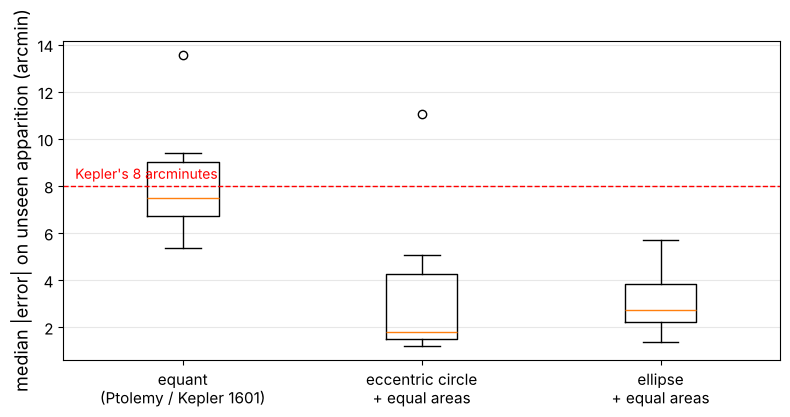

In [47]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([cv_scores[k] for k in cv_scores])
ax.set_xticks([1, 2, 3], ["equant\n(Ptolemy / Kepler 1601)",
                          "eccentric circle\n+ equal areas", "ellipse\n+ equal areas"])
ax.axhline(8, color="r", ls="--", lw=1)
ax.text(0.55, 8.3, "Kepler's 8 arcminutes", color="r")
ax.set_ylabel("median |error| on unseen apparition (arcmin)")
ax.grid(alpha=0.3, axis="y")
save_fig("cross_validation_boxplot")
plt.show()

## Fine-Tune Your Model

In [48]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {"loss": ["linear"]},
    {"loss": ["soft_l1", "cauchy"], "f_scale": [1.0, 3.0, 10.0]},
]
ellipse_reg = OrbitRegressor(model="ellipse", init=regs["ellipse"].params_)
grid_search = GridSearchCV(ellipse_reg, param_grid, cv=group_kfold,
                           scoring=medae_arcmin, return_train_score=True)
grid_search.fit(mars_prepared, mars_labels, groups=groups)
grid_search.best_params_

{'f_scale': 1.0, 'loss': 'soft_l1'}

In [49]:
cvres = grid_search.cv_results_
for mean_score, params in zip(cvres["mean_test_score"], cvres["params"]):
    print(f"{-mean_score:6.3f}'", params)

 6.907' {'loss': 'linear'}
 2.996' {'f_scale': 1.0, 'loss': 'soft_l1'}
 3.983' {'f_scale': 1.0, 'loss': 'cauchy'}
 3.124' {'f_scale': 3.0, 'loss': 'soft_l1'}
 3.147' {'f_scale': 3.0, 'loss': 'cauchy'}
 3.464' {'f_scale': 10.0, 'loss': 'soft_l1'}
 3.580' {'f_scale': 10.0, 'loss': 'cauchy'}


In [50]:
final_model = grid_search.best_estimator_
pd.Series(final_model.params_).round(4)

e_E            0.0191
varpi_E       91.8139
L_E          109.9334
P_E          365.2564
a_M            1.5266
e_M            0.0932
varpi_M      328.8561
L_M            1.2885
P_M          686.9929
i_M            1.8331
node_M        47.8927
obliquity     23.5486
eq_E           0.0340
eq_M           0.1800
dtype: float64

In [51]:
# Parameter uncertainties from the Jacobian of the residuals (Gauss-Newton covariance)
res = final_model.result_
dof = len(res.fun) - len(res.x)
sigma2 = np.median(np.abs(res.fun)) ** 2 / 0.4549          # robust noise estimate
cov = np.linalg.pinv(res.jac.T @ res.jac) * sigma2
free_names = [p for p in PARAMS if p != "P_E"]
uncert = pd.Series(np.sqrt(np.diag(cov)), index=free_names)
uncert[["a_M", "e_M", "P_M", "i_M", "e_E", "obliquity"]].round(4)

a_M          0.0004
e_M          0.0003
P_M          0.0096
i_M          0.0041
e_E          0.0005
obliquity    0.0066
dtype: float64

Saving figure residuals_plot


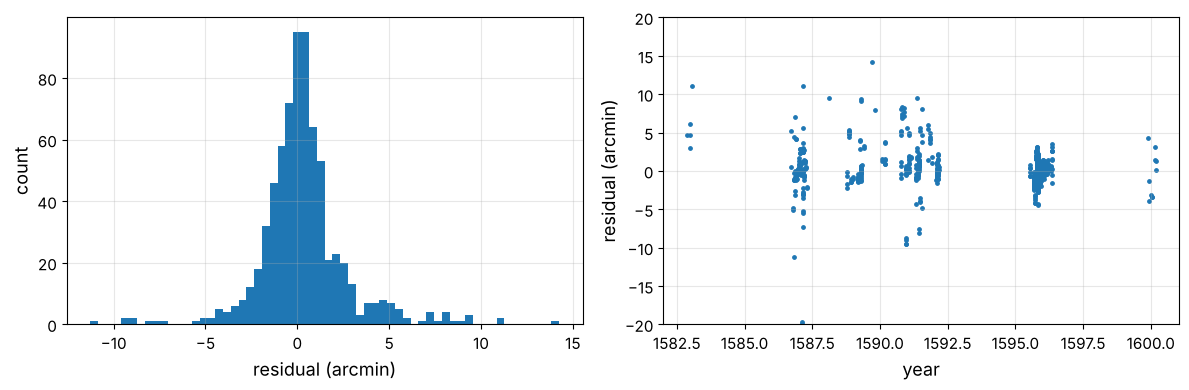

In [52]:
train_pred = final_model.predict(mars_prepared)
train_err = (mars_labels.values - train_pred) * 60
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_err[np.abs(train_err) < 15], bins=60)
axes[0].set_xlabel("residual (arcmin)"); axes[0].set_ylabel("count")
axes[1].scatter(mars_prepared.ravel() / 365.25 + 1590, train_err, s=6)
axes[1].set_ylim(-20, 20)
axes[1].set_xlabel("year"); axes[1].set_ylabel("residual (arcmin)")
for ax in axes: ax.grid(alpha=0.3)
save_fig("residuals_plot")
plt.show()

In [53]:
worst = mars.assign(residual_arcmin=train_err).loc[np.abs(train_err) > 15]
worst = worst.reindex(worst["residual_arcmin"].abs().sort_values(ascending=False).index)
print(len(worst), "observations are off by more than 15 arcmin")
worst[["year", "month", "day", "day_text", "time_text", "residual_arcmin"]].round(1).head(10)

33 observations are off by more than 15 arcmin


,year,month,day,day_text,time_text,residual_arcmin
882,1596,1,31,DIE 31 JANUARIJ.,H.6 M.57 1/3,-339.2
881,1596,1,31,DIE 31 JANUARIJ.,H.6 M.57 1/3,-338.9
41,1586,10,10,DIE 10 OCTOBRIS.,H.6 M.14,-126.4
42,1586,10,10,DIE 10 OCTOBRIS.,H.6 M.14,-126.3
96,1587,2,15,DIE 15 JANUARIJ. (FEB???),H.15 M.57,-75.3
339,1591,10,10,"DIE 10 OCTOBRIS, VESPERI.",H.6 M.26,67.1
95,1587,2,14,DIE 14 JANUARIJ (FEB???),H.16 M.45,-67.0
94,1587,2,14,DIE 14 JANUARIJ (FEB???),H.15 M.52,-66.5
340,1591,10,10,"DIE 10 OCTOBRIS, VESPERI.",H.6 M.26,66.4
162,1589,2,12,"DIE 12 FEBRUARIJ, MANE.",H.5 M.19,-66.2


Saving figure model_disagreement_plot


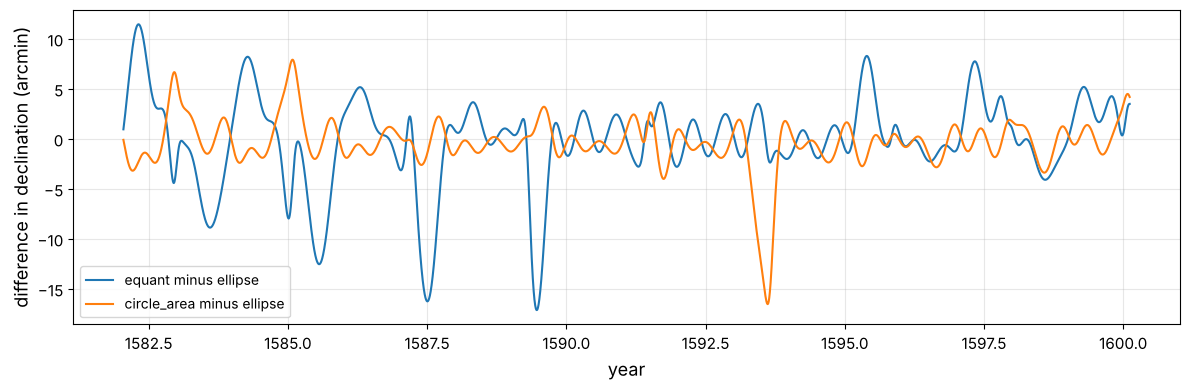

In [54]:
# Where do the models disagree? Predict the sky for every day of 1582-1600.
t_grid = mars_geo["jd"].values - T0
fig, ax = plt.subplots(figsize=(12, 4))
for name in ["equant", "circle_area"]:
    diff = (regs[name].predict(t_grid) - final_model.predict(t_grid)) * 60
    ax.plot(t_grid / 365.25 + 1590, diff, label=f"{name} minus ellipse")
ax.set_xlabel("year"); ax.set_ylabel("difference in declination (arcmin)")
ax.grid(alpha=0.3); ax.legend()
save_fig("model_disagreement_plot")
plt.show()

## Evaluate Your System on the Test Set

In [55]:
X_test = test_set.drop("declination", axis=1)
y_test = test_set["declination"].copy()
X_test_prepared = prep_pipeline.transform(X_test)
final_predictions = final_model.predict(X_test_prepared)
final_errors = (final_predictions - y_test.values) * 60
print("test MedAE  = %.2f arcmin" % np.median(np.abs(final_errors)))
inliers = np.abs(final_errors) < 15
print("test RMSE (without %d blunders) = %.2f arcmin" % ((~inliers).sum(),
      np.sqrt(np.mean(final_errors[inliers] ** 2))))

test MedAE  = 7.17 arcmin
test RMSE (without 61 blunders) = 6.08 arcmin


In [56]:
from scipy import stats

confidence = 0.95
abs_err = np.abs(final_errors[inliers])
mean = abs_err.mean()
interval = stats.t.interval(confidence, len(abs_err) - 1, loc=mean, scale=stats.sem(abs_err))
print(f"mean |error| = {mean:.2f}' , 95% CI = ({interval[0]:.2f}', {interval[1]:.2f}')")

mean |error| = 4.79' , 95% CI = (4.14', 5.44')


In [57]:
# How well could ANY model do on these observations? Compare Tycho with NASA's sky.
test_jd = X_test_prepared.ravel() + T0
nasa_on_test = np.interp(test_jd, mars_geo["jd"], mars_geo["dec"])
tycho_vs_nasa = (y_test.values - nasa_on_test) * 60
ours_vs_nasa = (final_predictions - nasa_on_test) * 60
print(f"Tycho vs NASA on the test rows (irreducible error): MedAE = {np.median(np.abs(tycho_vs_nasa)):.2f}'")
print(f"Our model vs NASA on the same dates:                 MedAE = {np.median(np.abs(ours_vs_nasa)):.2f}'")

Tycho vs NASA on the test rows (irreducible error): MedAE = 1.58'
Our model vs NASA on the same dates:                 MedAE = 6.94'


test set years: [np.int64(1584), np.int64(1585), np.int64(1593), np.int64(1594), np.int64(1595)]
Saving figure error_vs_distance_plot


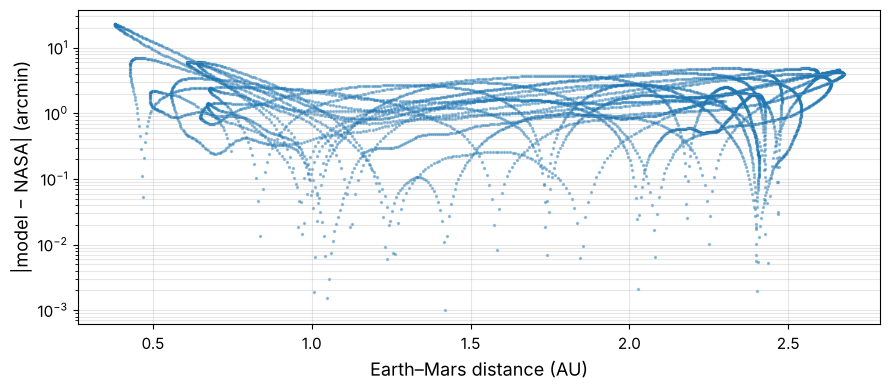

In [58]:
# Where is the model weakest? Error against NASA vs the Earth-Mars distance, 1582-1600
model_vs_nasa = (final_model.predict(t_grid) - mars_geo["dec"].values) * 60
test_years = sorted(test_set["year"].unique())
print("test set years:", test_years)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(mars_geo["delta"], np.abs(model_vs_nasa), s=2, alpha=0.4)
ax.set_xlabel("Earth–Mars distance (AU)")
ax.set_ylabel("|model − NASA| (arcmin)")
ax.set_yscale("log"); ax.grid(alpha=0.3, which="both")
save_fig("error_vs_distance_plot")
plt.show()

In [59]:
truth = np.interp(mars_geo["jd"].values, mars_geo["jd"].values, mars_geo["dec"].values)
our_sky = final_model.predict(t_grid)
d = (our_sky - truth) * 60
print(f"Our Tycho-trained model vs NASA/JPL, every day 1582-1600: "
      f"median |diff| = {np.median(np.abs(d)):.2f}', 95% within {np.percentile(np.abs(d), 95):.2f}'")
p = final_model.params_
modern = {"a_M": 1.5237, "e_M": 0.0934, "P_M": 686.98, "i_M": 1.85, "e_E": 0.0167,
          "obliquity": 23.494}
pd.DataFrame({"ours (Tycho data)": {k: p[k] for k in modern}, "modern value": modern}).round(4)

Our Tycho-trained model vs NASA/JPL, every day 1582-1600: median |diff| = 1.54', 95% within 4.80'


,ours (Tycho data),modern value
a_M,1.5266,1.5237
e_M,0.0932,0.0934
P_M,686.9929,686.9800
i_M,1.8331,1.8500
e_E,0.0191,0.0167
obliquity,23.5486,23.4940


In [60]:
from sklearn.base import clone

# Before launch: retrain the chosen model on ALL the data (training + test)
X_full = prep_pipeline.transform(tycho.drop("declination", axis=1))
y_full = tycho["declination"].values
full_model = clone(final_model).set_params(init=final_model.params_)
full_model.fit(X_full, y_full)
d_full = (full_model.predict(t_grid) - mars_geo["dec"].values) * 60
print(f"full model vs NASA, 1582-1600: median |diff| = {np.median(np.abs(d_full)):.2f}', "
      f"95% within {np.percentile(np.abs(d_full), 95):.2f}'")
pf = full_model.params_
pd.DataFrame({"trained on 80%": {k: p[k] for k in modern},
              "trained on 100%": {k: pf[k] for k in modern},
              "modern value": modern}).round(4)

full model vs NASA, 1582-1600: median |diff| = 0.87', 95% within 2.94'


,trained on 80%,trained on 100%,modern value
a_M,1.5266,1.5244,1.5237
e_M,0.0932,0.0938,0.0934
P_M,686.9929,686.9603,686.9800
i_M,1.8331,1.8437,1.8500
e_E,0.0191,0.0157,0.0167
obliquity,23.5486,23.5098,23.4940


In [61]:
X_law3 = np.log(harmony[["a_AU"]].values)
y_law3 = np.log(harmony["period_years"].values)
lin_reg = LinearRegression()
lin_reg.fit(X_law3, y_law3)
lin_reg.coef_, lin_reg.intercept_

(array([1.49852041]), np.float64(-0.000318342716054687))

In [62]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import LeaveOneOut, cross_val_score

for degree in (1, 2, 3):
    poly_reg = Pipeline([("poly", PolynomialFeatures(degree, include_bias=False)),
                         ("lin", LinearRegression())])
    scores = cross_val_score(poly_reg, X_law3, y_law3, cv=LeaveOneOut(),
                             scoring="neg_mean_squared_error")
    print(f"degree {degree}: LOO RMSE in log T = {np.sqrt(-scores.mean()):.4f}")

degree 1: LOO RMSE in log T = 0.0045
degree 2: LOO RMSE in log T = 0.0054
degree 3: LOO RMSE in log T = 0.0063


Saving figure third_law_fit_plot


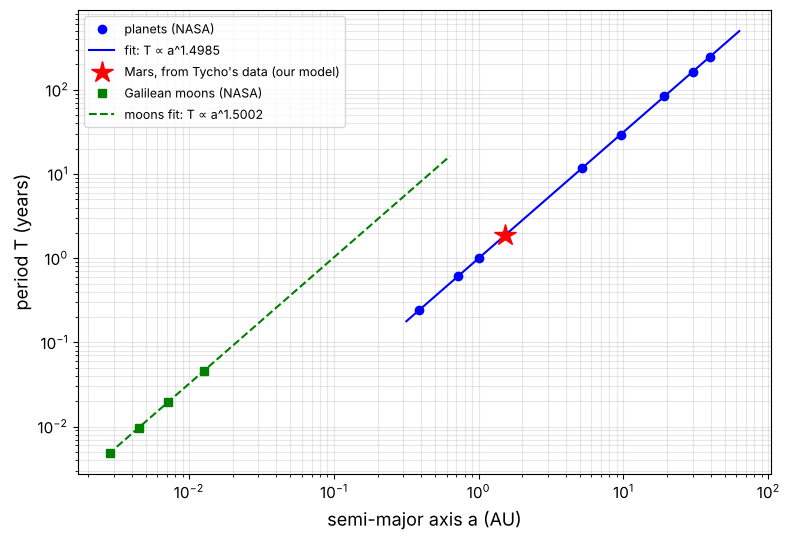

In [63]:
moons_a_AU = moons["a_thousand_km"] * 1e3 / AU_KM
moons_T = moons["period_days"] / 365.25
a_grid = np.logspace(-0.5, 1.8, 50)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.loglog(harmony["a_AU"], harmony["period_years"], "bo", label="planets (NASA)")
ax.loglog(a_grid, np.exp(lin_reg.predict(np.log(a_grid).reshape(-1, 1))), "b-",
          label=f"fit: T ∝ a^{lin_reg.coef_[0]:.4f}")
ax.loglog(pf["a_M"], pf["P_M"] / 365.2564, "r*", ms=16,
          label="Mars, from Tycho's data (our model)")
ax.loglog(moons_a_AU, moons_T, "gs", label="Galilean moons (NASA)")
m_reg = LinearRegression().fit(np.log(moons_a_AU.values).reshape(-1, 1), np.log(moons_T))
ax.loglog(a_grid / 100, np.exp(m_reg.predict(np.log(a_grid / 100).reshape(-1, 1))),
          "g--", label=f"moons fit: T ∝ a^{m_reg.coef_[0]:.4f}")
ax.set_xlabel("semi-major axis a (AU)"); ax.set_ylabel("period T (years)")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
save_fig("third_law_fit_plot")
plt.show()

In [64]:
# Kepler III with Newton: T² = 4π² a³ / (G M). Fix the slope at 3/2 and the
# intercept measures the central mass: c = mean(log T - 1.5 log a) = -½ log(GM/4π²)
c_sun = np.mean(np.log(harmony["period_years"]) - 1.5 * np.log(harmony["a_AU"]))
c_jup = np.mean(np.log(moons_T) - 1.5 * np.log(moons_a_AU))
print(f"M_Jupiter / M_Sun = {np.exp(2 * (c_sun - c_jup)):.6f}   (NASA: 0.000955)")

M_Jupiter / M_Sun = 0.000950   (NASA: 0.000955)


## Launch, Monitor, and Maintain Your System

Saving figure model_drift_plot


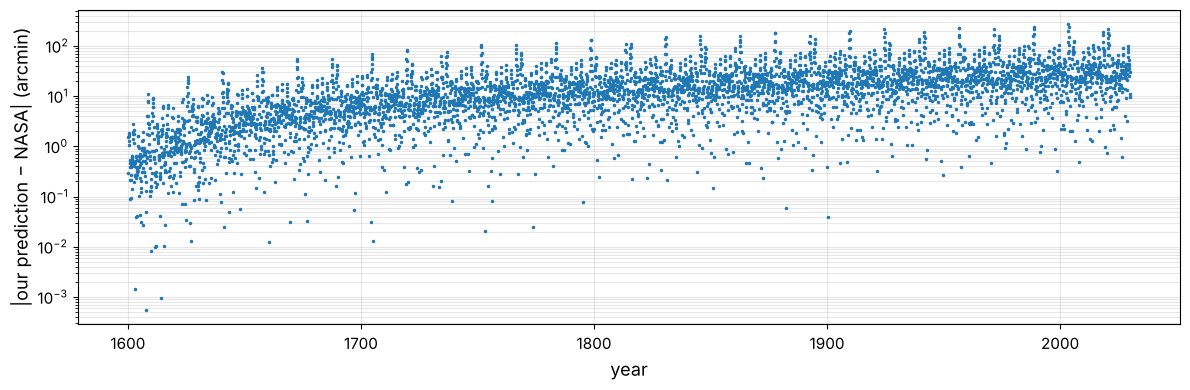

1600 median |error| =     0.5 arcmin
1650 median |error| =     3.5 arcmin
1700 median |error| =     7.6 arcmin
1800 median |error| =    11.8 arcmin
1900 median |error| =    21.5 arcmin
2000 median |error| =    24.0 arcmin
2025 median |error| =    28.4 arcmin


In [65]:
# Fetch NASA's Mars for 1600-2030 (one point every 30 days) and compare.
mars_modern = fetch_horizons("4", "1600-03-01", "2030-01-01", "30d", "2",
                             "horizons_mars_geocentric_1600_2030.csv")
mars_modern.columns = ["jd", "ra", "dec"]
t_future = mars_modern["jd"].values - T0
drift = (full_model.predict(t_future) - mars_modern["dec"].values) * 60
years = t_future / 365.25 + 1590
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(years, np.abs(drift), ".", ms=3)
ax.set_yscale("log")
ax.set_xlabel("year"); ax.set_ylabel("|our prediction − NASA| (arcmin)")
ax.grid(alpha=0.3, which="both")
save_fig("model_drift_plot")
plt.show()
for y0 in (1600, 1650, 1700, 1800, 1900, 2000, 2025):
    sel = (years > y0) & (years < y0 + 5)
    print(y0, f"median |error| = {np.median(np.abs(drift[sel])):7.1f} arcmin")

In [66]:
import json
os.makedirs("animations", exist_ok=True)
p = full_model.params_
anim = {"earth": {"a": 1.0, "e": p["e_E"], "varpi": p["varpi_E"], "L0": p["L_E"],
                  "P": p["P_E"]},
        "mars": {"a": p["a_M"], "e": p["e_M"], "varpi": p["varpi_M"], "L0": p["L_M"],
                 "P": p["P_M"], "i": p["i_M"], "node": p["node_M"]},
        "equant_mars": {k: regs["equant"].params_[k] for k in ["a_M", "e_M", "eq_M"]},
        "planets": harmony[["a_AU", "period_years", "eccentricity"]].round(5)
                    .reset_index().rename(columns={"index": "name"}).to_dict("records"),
        "law3_slope": float(lin_reg.coef_[0]),
        "obliquity": p["obliquity"]}
all_t = prep_pipeline.transform(tycho).ravel()            # every observation, for the sky panel
anim["tycho"] = {"t_min": float(all_t.min()), "t_max": float(all_t.max()),
                 "obs": np.c_[all_t.round(2), tycho["declination"].round(4)].tolist()}
with open(os.path.join("animations", "fitted_parameters.json"), "w") as f:
    json.dump(anim, f, indent=1, default=float)
print(json.dumps(anim["mars"], default=float))

{"a": 1.524446827402435, "e": 0.09383816134925123, "varpi": 328.27510065356284, "L0": 1.26078355970011, "P": 686.9602884229988, "i": 1.8437224576080242, "node": 47.0992456203707}
